# Telco Churn: EDA, модельдерді салыстыру және бағалау
ЕГЖ, 5-нұсқа. Нәтижелер `reports/results.json` және `reports/figures/` ішінде (`python -m src.train` жасайды).

In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd
from IPython.display import Image, display
from src.train import load, FEATURES
df = load()
print(df.shape)
df[FEATURES].isna().sum()[lambda s: s>0]

(7043, 22)


TotalCharges    11
dtype: int64

## EDA

In [2]:
print(df['Churn'].value_counts(normalize=True))
df.groupby('Contract')['y'].mean()

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: y, dtype: float64

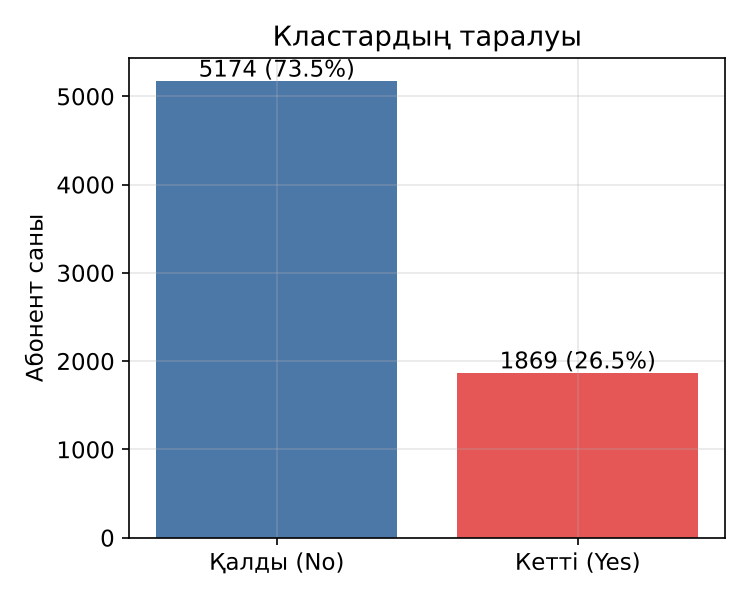

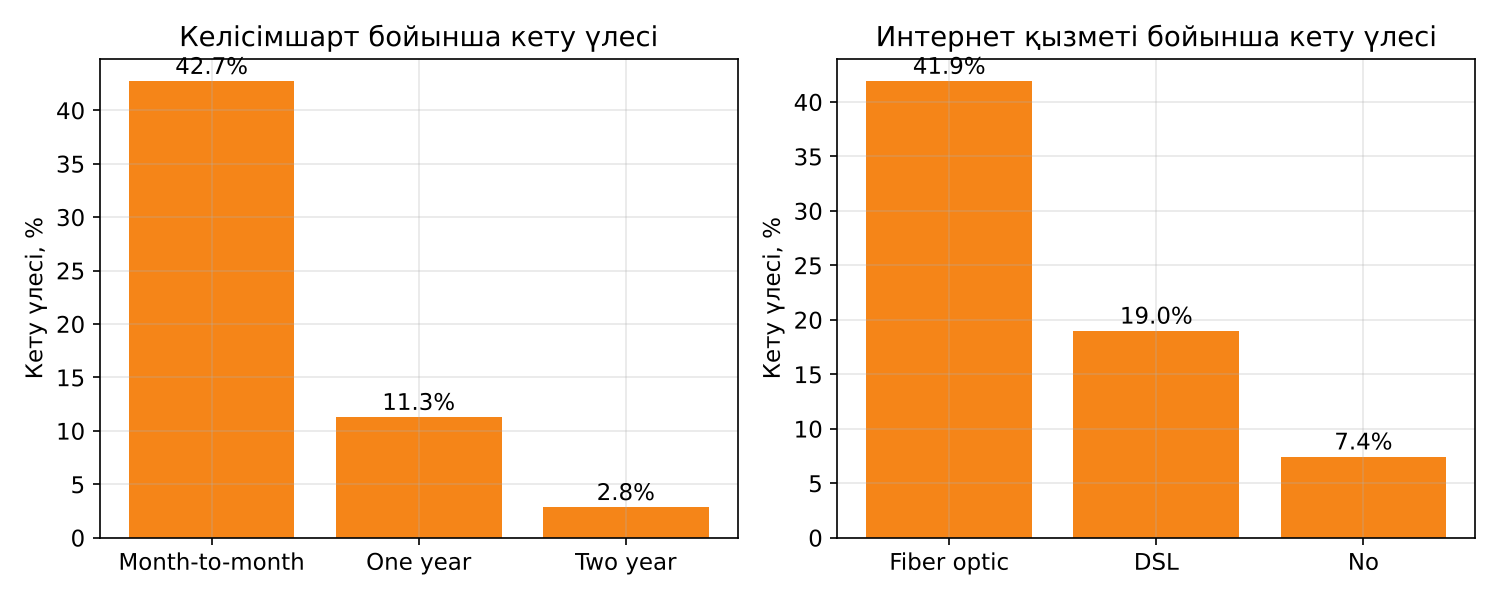

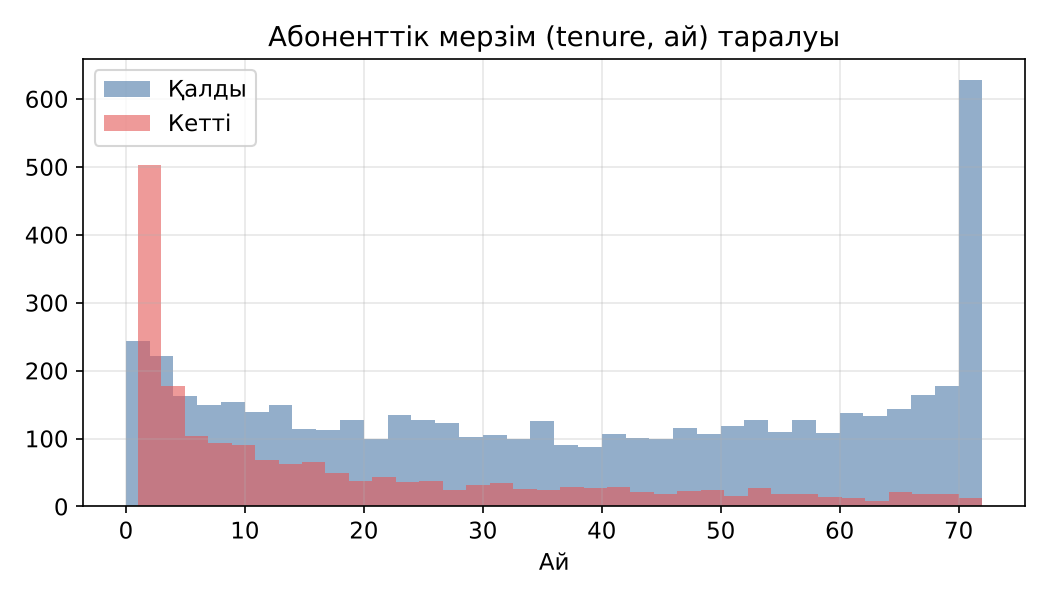

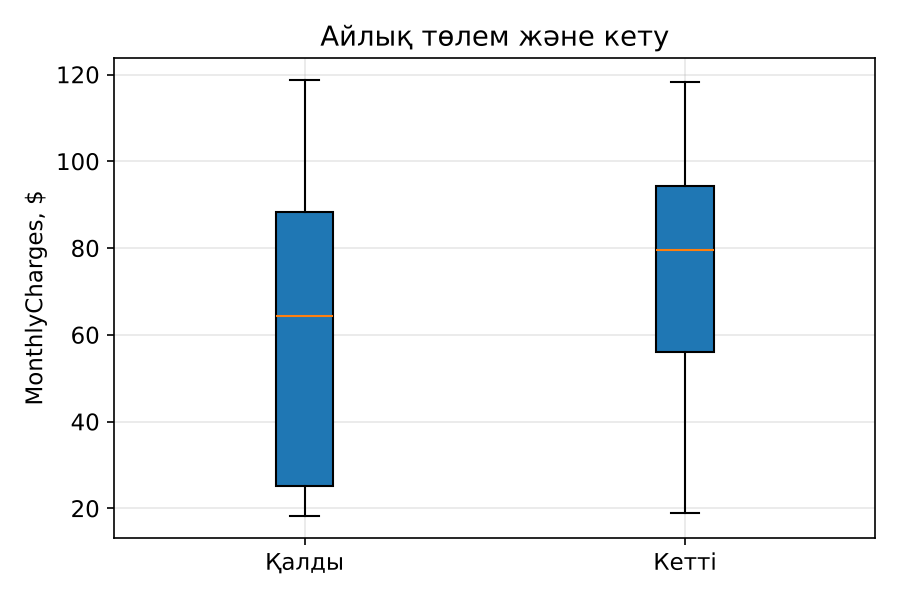

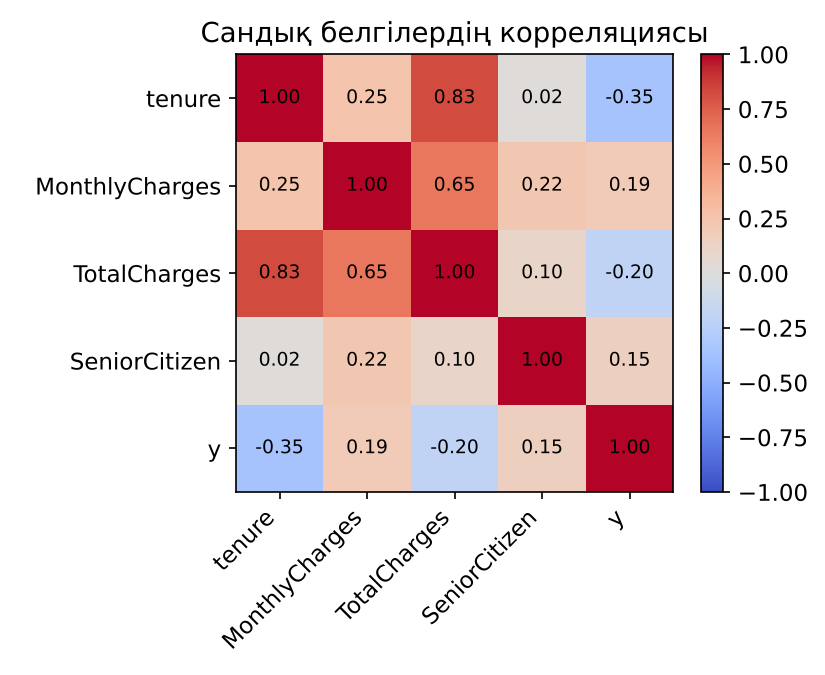

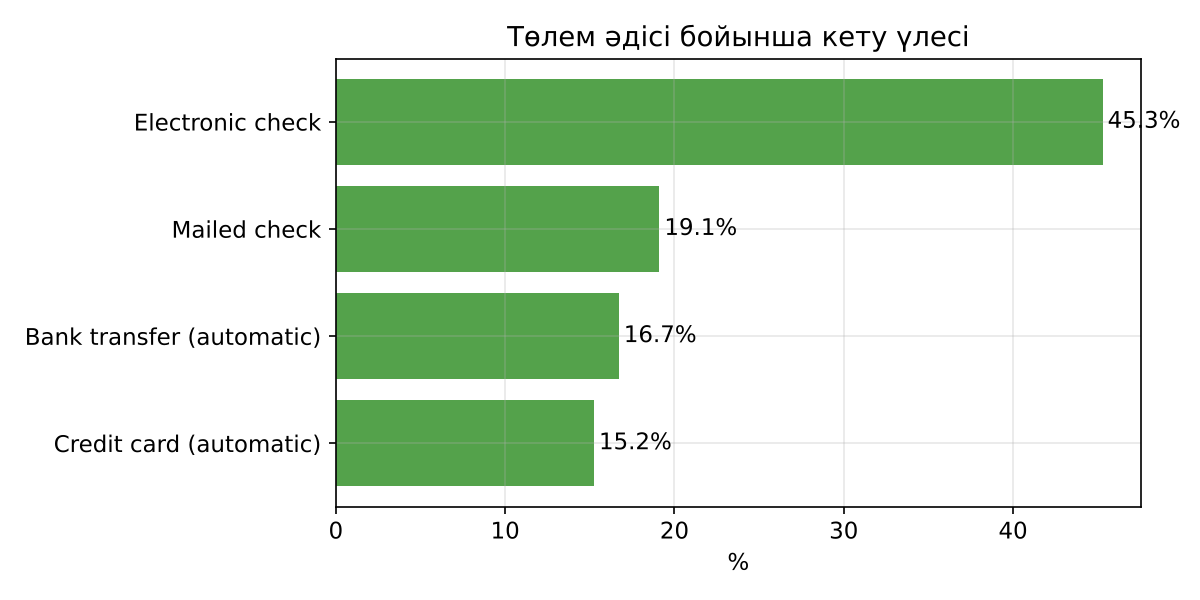

In [3]:
for f in ['eda1_class','eda2_contract_internet','eda3_tenure','eda4_monthly_box','eda5_corr','eda6_payment']:
    display(Image(f'../reports/figures/{f}.png'))

## Модельдерді салыстыру (5-fold CV, GridSearchCV, PR-AUC)

In [4]:
res = json.load(open('../reports/results.json'))
pd.DataFrame(res['comparison'])

,model,best_params,cv_pr_auc,test_pr_auc,test_roc_auc
0,Logistic Regression,{'C': 1},0.6600,0.6326,0.8413
1,Random Forest,"{'max_depth': None, 'min_samples_leaf': 10, 'n...",0.6611,0.6504,0.8435
2,Gradient Boosting,"{'learning_rate': 0.03, 'max_depth': 5, 'max_i...",0.6688,0.6567,0.8439


## Бағалау: шекті мәнді шығын бойынша таңдау

In [5]:
print('threshold(cost)=', res['threshold_cost'], ' threshold(F1)=', res['threshold_f1'])
pd.DataFrame([res['test_at_0.5'], res['test_at_cost_thr'], res['test_at_f1_thr']])

threshold(cost)= 0.41  threshold(F1)= 0.59


,threshold,tn,fp,fn,tp,precision,recall,f1,cost
0,0.50,766,269,75,299,0.5264,0.7995,0.6348,28450.0
1,0.41,688,347,54,320,0.4798,0.8556,0.6148,28150.0
2,0.59,834,201,117,257,0.5611,0.6872,0.6178,33450.0


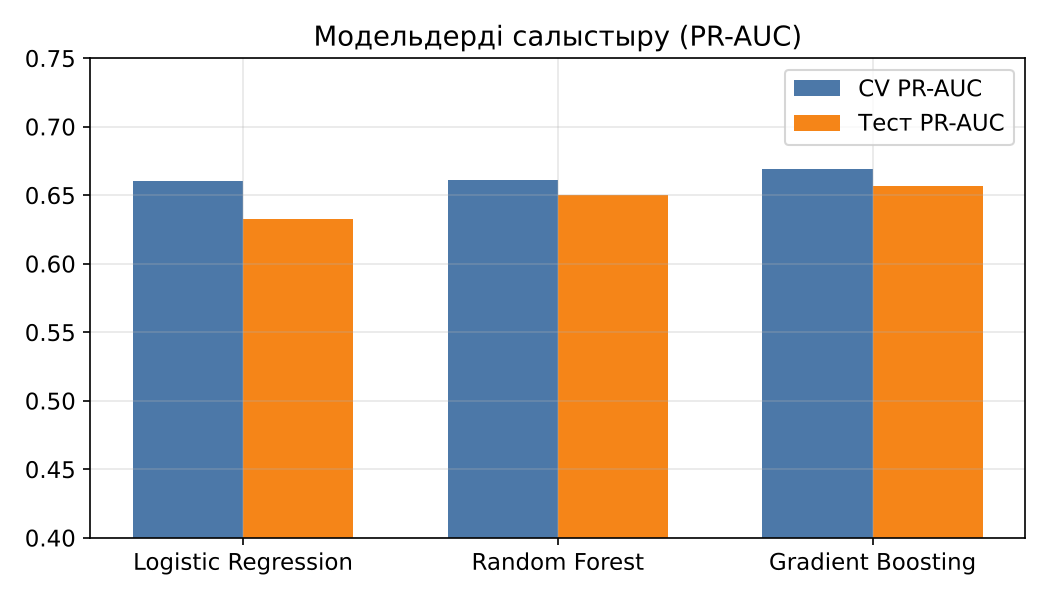

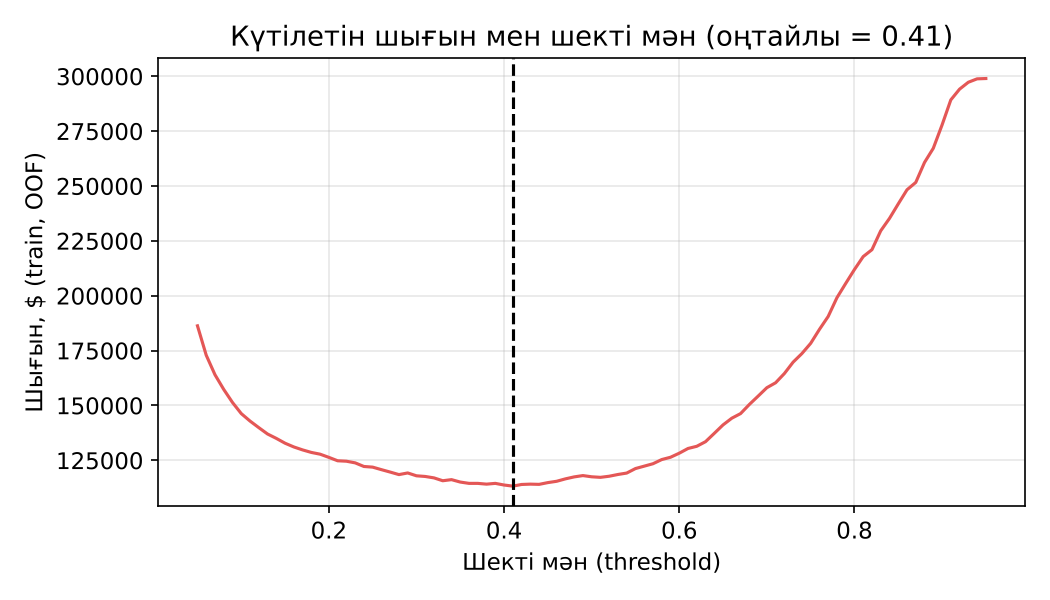

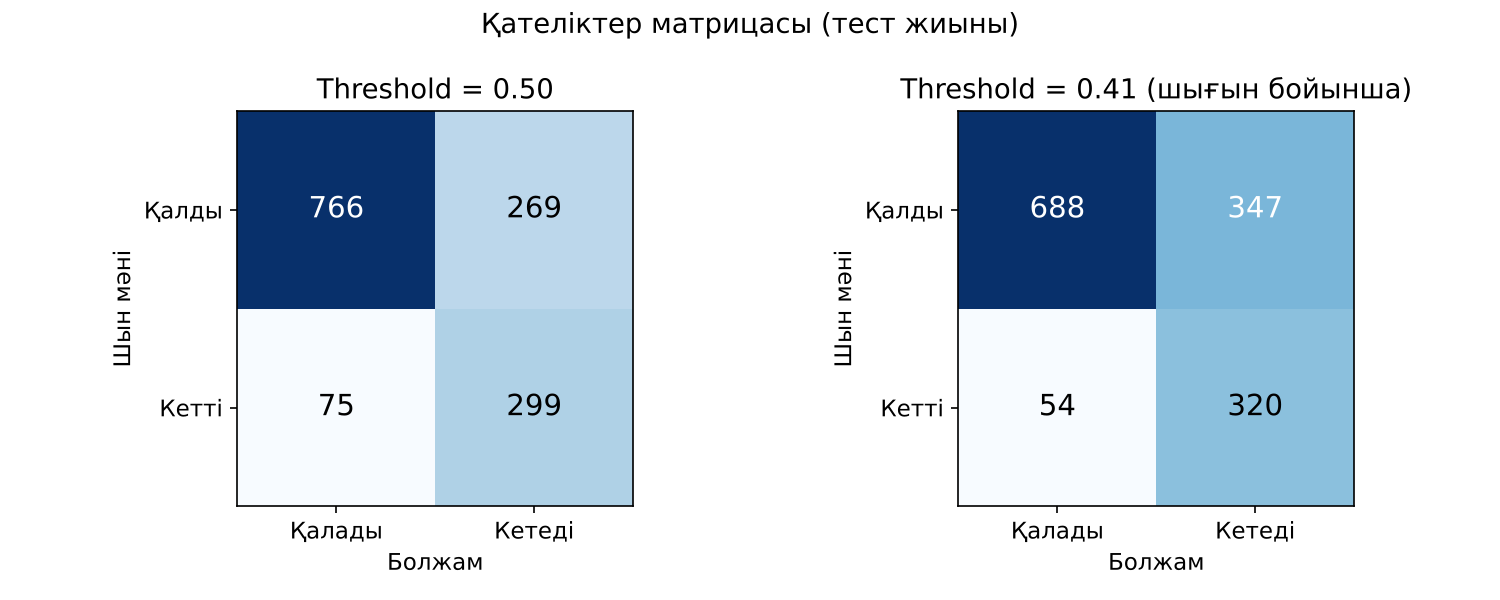

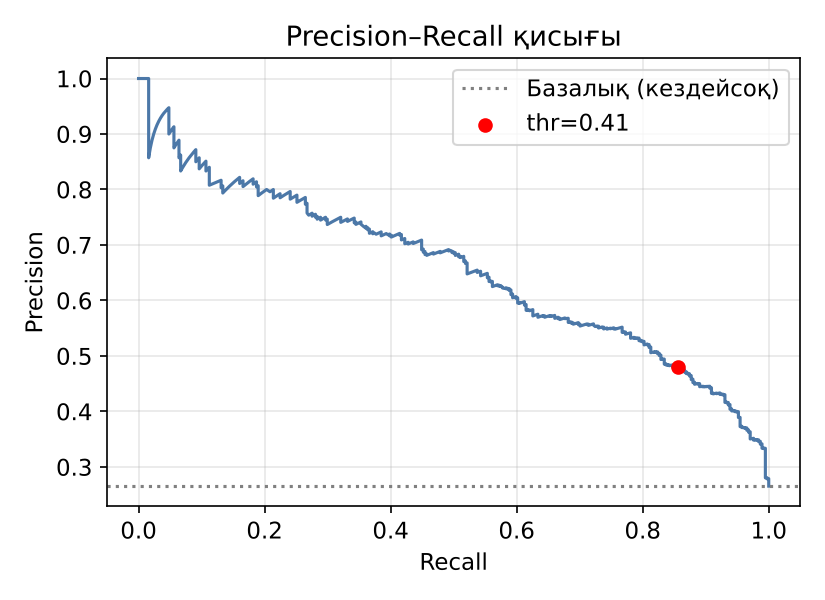

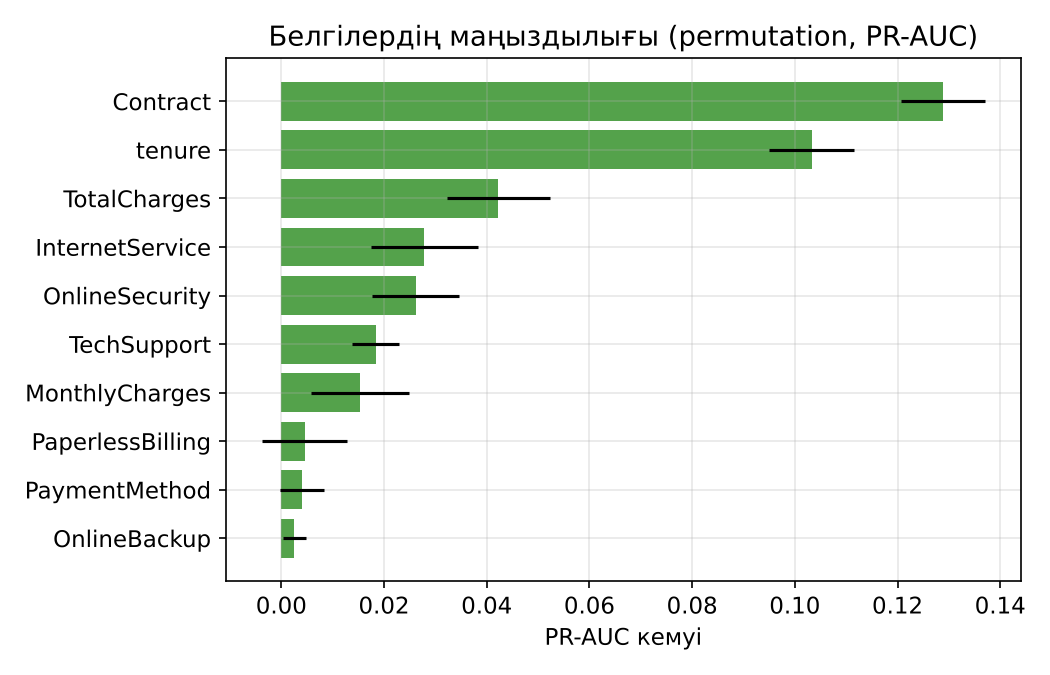

In [6]:
for f in ['model_compare','model_threshold_cost','model_confusion','model_pr_curve','model_importance']:
    display(Image(f'../reports/figures/{f}.png'))

## Ең сенімді қателер (5 мысал)

In [7]:
pd.DataFrame(res['worst5'])[['tenure','MonthlyCharges','Contract','InternetService','PaymentMethod','y_true','p']]

,tenure,MonthlyCharges,Contract,InternetService,PaymentMethod,y_true,p
0,55,57.55,Two year,DSL,Bank transfer (automatic),1,0.045411
1,72,92.45,Two year,DSL,Credit card (automatic),1,0.047081
2,1,79.15,Month-to-month,Fiber optic,Mailed check,0,0.923060
3,2,91.45,Month-to-month,Fiber optic,Electronic check,0,0.912371
4,2,84.05,Month-to-month,Fiber optic,Electronic check,0,0.911023
